## Clase 05

#### Simulación de Procesos Financieros

- José Armando Melchor Soto
- Nicole Getzabel Flores Godines 
- Ana Paula Moreno Haro

31/08/2026

---

### Libraries 

In [ ]:
import random

import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import yfinance as yf 
from scipy.stats import norm


---

In [46]:
data = yf.download('MSFT' , start = '2026-01-01' , end = '2026-08-31', progress= False)['Close']
data

C:\Users\ppmel\AppData\Local\Temp\ipykernel_976\2942569398.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download('MSFT' , start = '2026-01-01' , end = '2026-08-31', progress= False)['Close']


Ticker,MSFT
Date,
2026-01-02,469.958496
2026-01-05,469.869049
2026-01-06,475.493378
2026-01-07,480.422150
2026-01-08,475.095917
...,...
2026-08-24,487.309998
2026-08-25,491.709991
2026-08-26,496.369995


In [47]:
data = data.sort_index()
# Train: 4 meses
train_start = '2026-01-01'
train_end   = '2026-04-30'

# Test: 2 meses
test_start  = '2026-05-01'
test_end    = '2026-06-30'

In [48]:
train = data.loc[train_start:train_end]
test = data.loc[test_start:test_end]


In [49]:
rets = np.log(train / train.shift(1)).dropna()
mu = rets.mean() * 252  
std = rets.std() * np.sqrt(252)  

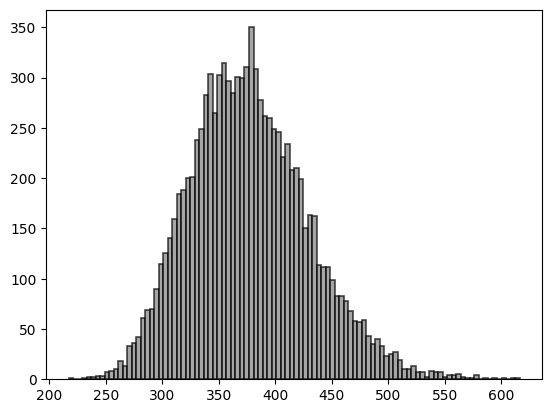

In [50]:
n_simulations = 10000

S0 = train['MSFT'].iloc[-1]
T = len(test) / 252


Z = np.random.normal(0, 1, n_simulations)

St = S0 * np.exp(
    (mu.values[0] - 0.5 * std.values[0]**2) * T
    + std.values[0] * np.sqrt(T) * Z
)

plt.hist(St, bins= 100,  density=False, color='grey', alpha=0.7, edgecolor='black' , linewidth=1.2)
plt.show()

In [51]:
S0

np.float64(406.1341552734375)

---


### Con semilla 30

In [56]:
random.seed(30)

In [52]:
precio_30_abril_2026 = train.loc['2026-04-30', 'MSFT']
print(f"El precio de cierre de Microsoft (MSFT) el 30 de abril de 2026 fue: {precio_30_abril_2026}")

El precio de cierre de Microsoft (MSFT) el 30 de abril de 2026 fue: 406.1341552734375


In [53]:
peor_precio = St.min()
print(f"El peor precio (mínimo) en las simulaciones: {peor_precio}")


El peor precio (mínimo) en las simulaciones: 217.1155722099898


In [54]:
mejor_precio = St.max()
print(f"El mejor precio (máximo) en las simulaciones: {mejor_precio}")

El mejor precio (máximo) en las simulaciones: 616.0701905095694


In [55]:
percentiles = np.percentile(St, [5, 25, 50, 75, 95])
print(f"Percentiles (5%, 25%, 50%, 75%, 95%): {percentiles}") 

Percentiles (5%, 25%, 50%, 75%, 95%): [297.85642293 340.20881549 373.56012936 410.03212153 469.64986328]


---

### Con semilla 42

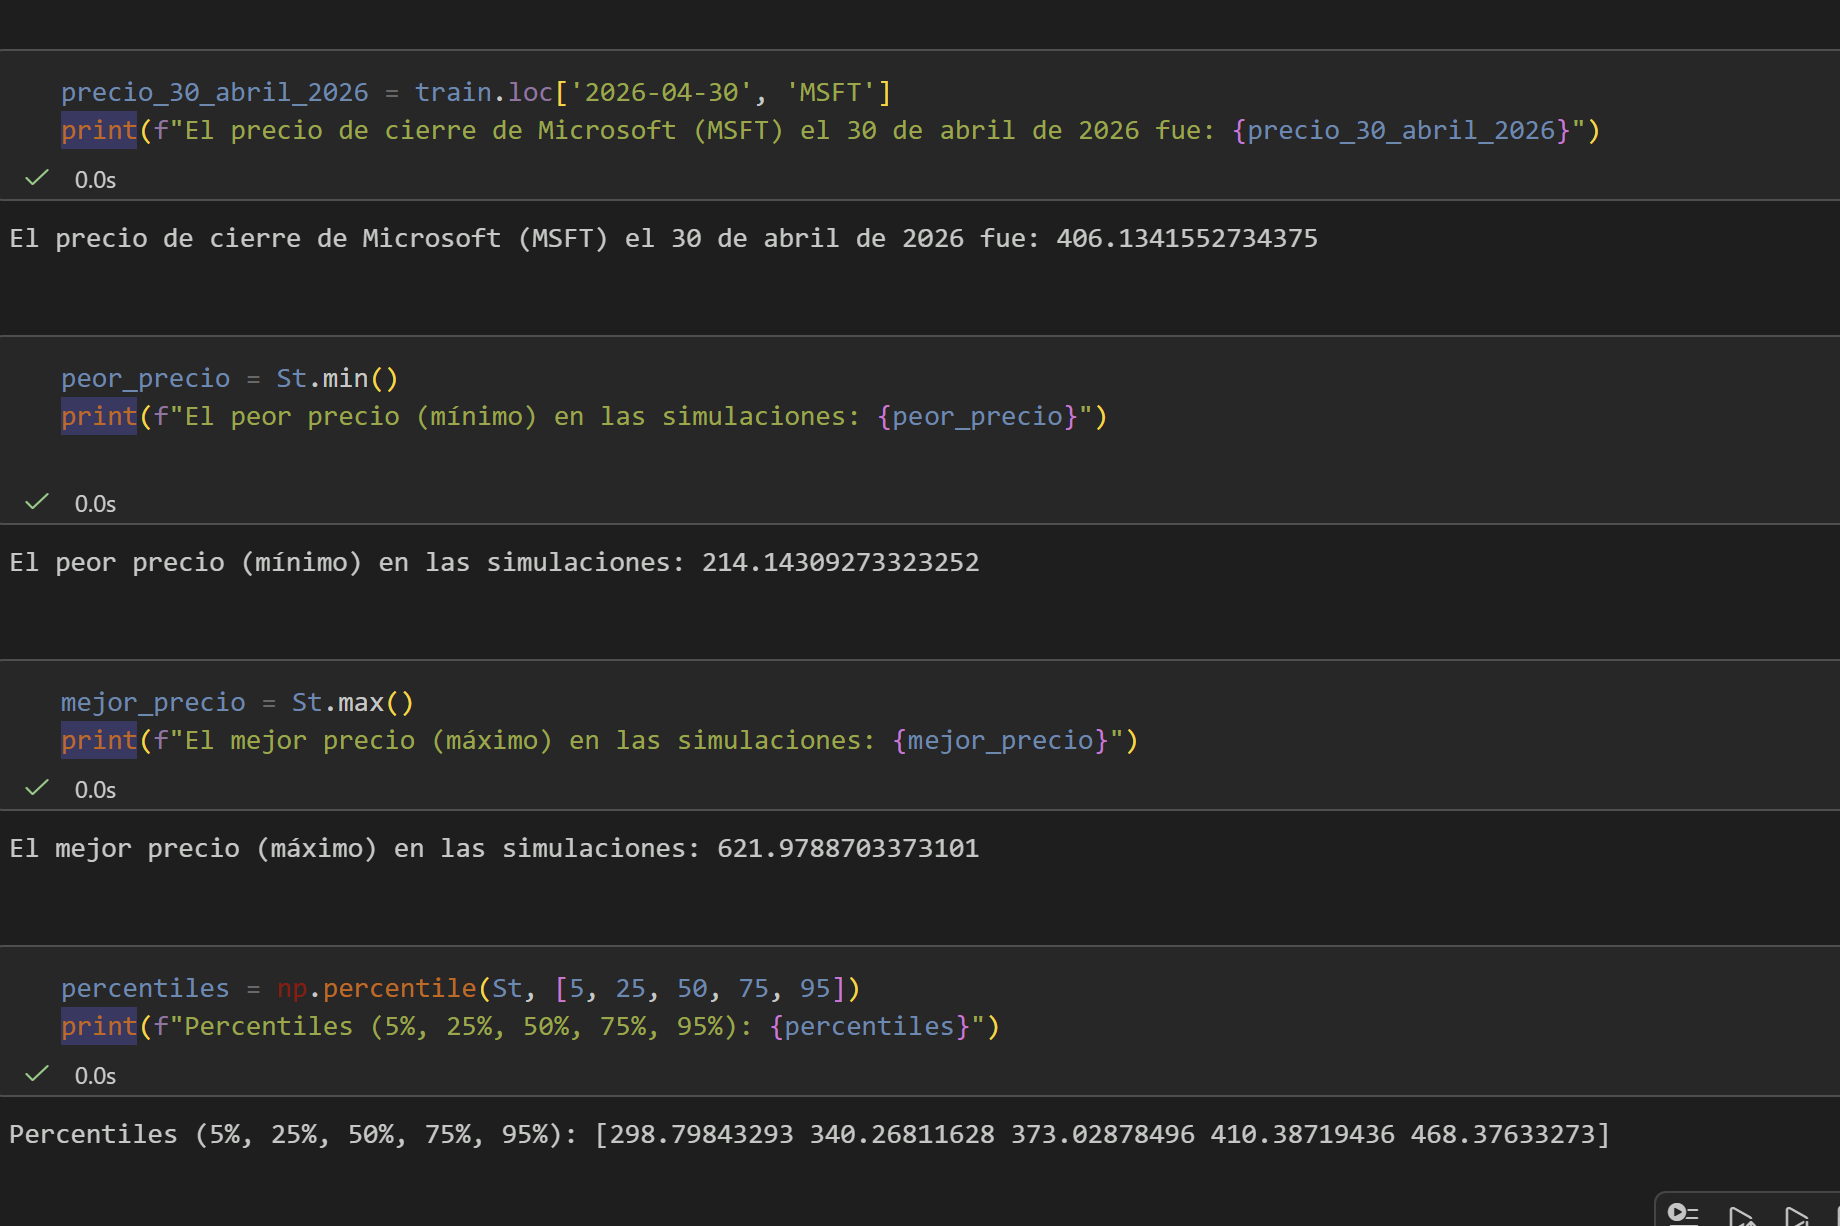